In [1]:


import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import seaborn as sns #visualization
import matplotlib.pyplot as plt #visualization
%matplotlib inline
import plotly.express as px
import plotly.graph_objects as go
import plotly.offline as py
import plotly.express as px

import warnings
warnings.filterwarnings("ignore")



import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))



/kaggle/input/visemtracking/image001.jpg
/kaggle/input/visemtracking/participant_related_data_Train.csv
/kaggle/input/visemtracking/sex_hormones_Train.csv
/kaggle/input/visemtracking/semen_analysis_data_Train.csv
/kaggle/input/visemtracking/tellekamer 2 - orientering - finne celler.avi
/kaggle/input/visemtracking/fatty_acids_spermatoza_Train.csv
/kaggle/input/visemtracking/fatty_acids_serum_Train.csv
/kaggle/input/visemtracking/vlcsnap-2019-08-16-06h53m30s393.png
/kaggle/input/visemtracking/sperm_counts_per_frame.csv
/kaggle/input/visemtracking/visem-extracted-30s-selected-20-videos-excluding-first-30s/visem-extracted-30s-selected-20-videos-excluding-first-30s/60_150_180.mp4
/kaggle/input/visemtracking/visem-extracted-30s-selected-20-videos-excluding-first-30s/visem-extracted-30s-selected-20-videos-excluding-first-30s/35_30_60.mp4
/kaggle/input/visemtracking/visem-extracted-30s-selected-20-videos-excluding-first-30s/visem-extracted-30s-selected-20-videos-excluding-first-30s/30_150_180.

In [2]:
df = pd.read_csv("/kaggle/input/visemtracking/sex_hormones_Train.csv", low_memory=False, encoding ='utf8',sep=",")

df.head()

,ID,Seminal plasma anti-Müllerian hormone (AMH) (pmol/L),Serum total testosterone (nmol/L),Serum oestradiol (nmol/L),"Serum sex hormone-binding globulin, SHBG (nmol/L)","Serum follicle-stimulating hormone, FSH (IU/L)","Serum Luteinizing hormone, LH (IU/L)",Serum inhibin B (ng/L),"Serum anti-Müllerian hormone, AMH (pmol/L)"
0,11,69,18.4,0.15,30,3.35,3.46,197,14
1,12,1,12.8,0.14,23,3.36,2.24,194,44
2,13,131,25.8,0.18,39,4.68,8.90,194,38
3,14,1,11.4,0.16,16,8.39,3.06,58,10
4,15,5,23.9,0.14,33,5.78,2.58,129,29


In [3]:
df1 = pd.read_csv("/kaggle/input/visemtracking/participant_related_data_Train.csv", low_memory=False, encoding ='utf8',sep=",")

df1.head()

,ID,Abstinence time(days),Body mass index (kg/m²),Age (years)
0,11,3,28.8,41
1,12,3.5,29.8,30
2,13,1,28.1,44
3,14,3,34.7,40
4,15,4,30.9,39


In [4]:
df2 = pd.read_csv("/kaggle/input/visemtracking/sex_hormones_Train.csv", low_memory=False, encoding ='utf8',sep=",")

df2.head()

,ID,Seminal plasma anti-Müllerian hormone (AMH) (pmol/L),Serum total testosterone (nmol/L),Serum oestradiol (nmol/L),"Serum sex hormone-binding globulin, SHBG (nmol/L)","Serum follicle-stimulating hormone, FSH (IU/L)","Serum Luteinizing hormone, LH (IU/L)",Serum inhibin B (ng/L),"Serum anti-Müllerian hormone, AMH (pmol/L)"
0,11,69,18.4,0.15,30,3.35,3.46,197,14
1,12,1,12.8,0.14,23,3.36,2.24,194,44
2,13,131,25.8,0.18,39,4.68,8.90,194,38
3,14,1,11.4,0.16,16,8.39,3.06,58,10
4,15,5,23.9,0.14,33,5.78,2.58,129,29


In [5]:
df3 = pd.read_csv("/kaggle/input/visemtracking/fatty_acids_spermatoza_Train.csv", low_memory=False, encoding ='utf8',sep=",")

df3.head()

,ID,Sperm C14:0 (myristic acid),Sperm C15:0 (pentadecanoic acid),Sperm C16:0 (palmitic acid),Sperm C16:1 n-7 (palmitoleic acid),Sperm C17:0,Sperm C18:0 (stearic acid),Sperm C18:1 trans n-6 to n-11,Sperm C18:1 n-9 (oleic acid),Sperm C18:1 n-7 to n-11,...,Sperm C20:1 n-9,Sperm C20:2 n-6,Sperm C22:0,Sperm C20:3 n-6,Sperm C20:4 n-6 and C22:1 n-9 combined,"Sperm C20:5 n-3 (eicosapentaenoic acid, EPA)",Sperm C24:0,Sperm C24:1 n-9,"Sperm C22:5 n-3 (docosapentaenoic acid, DPA)","Sperm C22:6,n3 (docosahexaenoic acid, DHA)"
0,11,1.8,0.2,21.6,1.7,0.2,7.5,1.7,21.6,2.7,...,0.5,0.6,1.2,1.7,1.6,0.02,1.0,1.2,0.9,18.6
1,12,1.3,0.2,23.5,1.1,0.3,8.8,1.1,13.2,2.3,...,0.4,0.5,1.6,1.8,2.4,0.08,0.9,1.4,2.0,25.0
2,13,1.8,0.2,20.3,1.7,0.2,8.7,2.2,23.2,2.5,...,0.5,0.4,1.4,1.9,2.0,0.07,1.2,1.3,0.8,16.1
3,14,1.4,0.2,18.4,1.2,0.3,9.2,2.0,26.1,1.7,...,0.8,0.4,2.2,1.0,4.2,0.31,2.9,3.8,0.8,3.6
4,15,1.7,0.2,24.0,1.4,0.3,8.4,1.3,15.3,3.0,...,0.7,0.6,2.3,1.7,2.1,0.06,1.9,1.8,1.0,16.0


In [6]:
df4 = pd.read_csv("/kaggle/input/visemtracking/fatty_acids_serum_Train.csv", low_memory=False, encoding ='utf8',sep=",")

df4.head()

,ID,Serum C14:0 (myristic acid),Serum C16:0 (palmitic acid),Serum C16:1 (palmitoleic acid),Serum C18:0 (stearic acid),Serum C18:1 n-9 (oleic acid),Serum total C18:1,"Serum C18:2 n-6 (linoleic acid, LA)","Serum C18:3 n-6 (gamma-linoleic acid, GLA)",Serum C20:1 n-9,Serum C20:2 n-6,Serum C20:3 n-6,Serum C20:4 n-6,"Serum C20:5 n-3 (eicosapentaenoic acid, EPA)","Serum C22:5 n-3 (docosapentaenoic acid, DPA)","Serum C22:6 n-3 (docosahexaenoic acid, DHA)"
0,11,0.26,29.64,0.37,14.92,7.43,9.02,23.22,0.14,0.19,0.37,2.91,9.00,1.63,1.22,7.11
1,12,0.17,29.77,0.45,13.99,6.66,8.23,18.50,0.15,0.18,0.27,1.51,12.66,4.11,1.40,8.61
2,13,0.20,29.22,0.48,15.34,8.32,9.90,20.98,0.29,0.13,0.31,2.10,9.57,3.39,1.06,7.01
3,14,0.31,28.76,0.49,17.03,7.73,9.37,22.50,0.20,0.09,0.27,3.51,10.75,0.89,1.04,4.80
4,15,0.26,28.94,0.41,14.79,11.45,13.47,18.84,0.20,0.11,0.27,3.03,11.71,1.33,1.28,5.36


In [7]:
df.columns.tolist()

['ID',
 'Seminal plasma anti-Müllerian hormone (AMH) (pmol/L)',
 'Serum total testosterone (nmol/L)',
 'Serum oestradiol (nmol/L)',
 'Serum sex hormone-binding globulin, SHBG (nmol/L)',
 'Serum follicle-stimulating hormone, FSH (IU/L)',
 'Serum Luteinizing hormone, LH (IU/L)',
 'Serum inhibin B (ng/L)',
 'Serum anti-Müllerian hormone, AMH (pmol/L)']

#Rename columns to avoid overlapping of the features names. (clumsy charts)

In [8]:
df = df.rename(columns={'Seminal plasma anti-Müllerian hormone (AMH) (pmol/L)':'amh', 'Serum total testosterone (nmol/L)': 'testosterone', 'Serum oestradiol (nmol/L)': 'oestradiol', 'Serum sex hormone-binding globulin, SHBG (nmol/L)': 'shbg', 'Serum follicle-stimulating hormone, FSH (IU/L)': 'fsh', 'Serum Luteinizing hormone, LH (IU/L)': 'lh', 'Serum inhibin B (ng/L)': 'inhibinB', 'Serum anti-Müllerian hormone, AMH (pmol/L)': 'serumAMH', 'ID': 'id'})

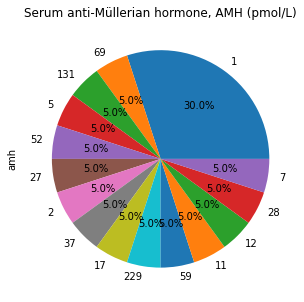

In [9]:
plt.figure(1, figsize=(5,5))
df['amh'].value_counts().plot.pie(autopct="%1.1f%%")
plt.title('Serum anti-Müllerian hormone, AMH (pmol/L)');

In [10]:
#Visualize some of the original dimensions

features = ["serumAMH", "fsh", "lh", "shbg", "oestradiol"]

fig = px.scatter_matrix(
    df,
    dimensions=features,
    color="testosterone"
)
fig.update_traces(diagonal_visible=False)
fig.show()

In [11]:
#Visualize some of the principal components

from sklearn.decomposition import PCA


features = ["serumAMH", "oestradiol", "shbg", "lh"]

pca = PCA()
components = pca.fit_transform(df[features])
labels = {
    str(i): f"PC {i+1} ({var:.1f}%)"
    for i, var in enumerate(pca.explained_variance_ratio_ * 100)
}

fig = px.scatter_matrix(
    components,
    labels=labels,
    dimensions=range(4),
    color=df["testosterone"]
)
fig.update_traces(diagonal_visible=False)
fig.show()

#Visualize a subset of the principal components

In [12]:
#Visualize a subset of the principal components

n_components = 4

pca = PCA(n_components=n_components)
components = pca.fit_transform(df)

total_var = pca.explained_variance_ratio_.sum() * 100

labels = {str(i): f"PC {i+1}" for i in range(n_components)}
labels['color'] = 'Median Nmol'  #nanomoles (nmol) per liter (L)? I didn't get color, how it works?

fig = px.scatter_matrix(
    components,
    color=df.testosterone,
    dimensions=range(n_components),
    labels=labels,
    title=f'Total Explained Variance: {total_var:.2f}%',
)
fig.update_traces(diagonal_visible=False)
fig.show()

In [13]:
#2D PCA Scatter Plot

X = df[["serumAMH", "oestradiol", "shbg", "lh"]]

pca = PCA(n_components=2)
components = pca.fit_transform(X)

fig = px.scatter(components, x=0, y=1, color=df['testosterone'])
fig.show()

#Visualize PCA with px scatter 3D

In [14]:
#Visualize PCA with px.scatter_3d

X = df[["oestradiol", "shbg", "lh"]]

pca = PCA(n_components=3)
components = pca.fit_transform(X)

total_var = pca.explained_variance_ratio_.sum() * 100

fig = px.scatter_3d(
    components, x=0, y=1, z=2, color=df['testosterone'],
    title=f'Total Explained Variance: {total_var:.2f}%',
    labels={'0': 'PC 1', '1': 'PC 2', '2': 'PC 3'}
)
fig.show()

In [15]:
#Plotting explained variance

pca = PCA()
pca.fit(df)
exp_var_cumul = np.cumsum(pca.explained_variance_ratio_)

px.area(
    x=range(1, exp_var_cumul.shape[0] + 1),
    y=exp_var_cumul,
    labels={"x": "# Components", "y": "Explained Variance"}
)

In [16]:
features = ["testosterone", "shbg", "serumAMH"]
X = df[features]

pca = PCA(n_components=2)
components = pca.fit_transform(X)

loadings = pca.components_.T * np.sqrt(pca.explained_variance_)

fig = px.scatter(components, x=0, y=1, color=df['oestradiol'])

for i, feature in enumerate(features):
    fig.add_shape(
        type='line',
        x0=0, y0=0,
        x1=loadings[i, 0],
        y1=loadings[i, 1]
    )
    fig.add_annotation(
        x=loadings[i, 0],
        y=loadings[i, 1],
        ax=0, ay=0,
        xanchor="center",
        yanchor="bottom",
        text=feature,
    )
fig.show()

In [17]:
fig = px.histogram(df, x="testosterone", title='Serum total testosterone (nmol/L)')
                   
fig.show()

In [18]:
fig = px.scatter(df, x="testosterone", y="amh", title='Testosterone vs Seminal plasma anti-Müllerian hormone (AMH) (pmol/L)')
fig.show()

#Correlation map, Method: Kendall

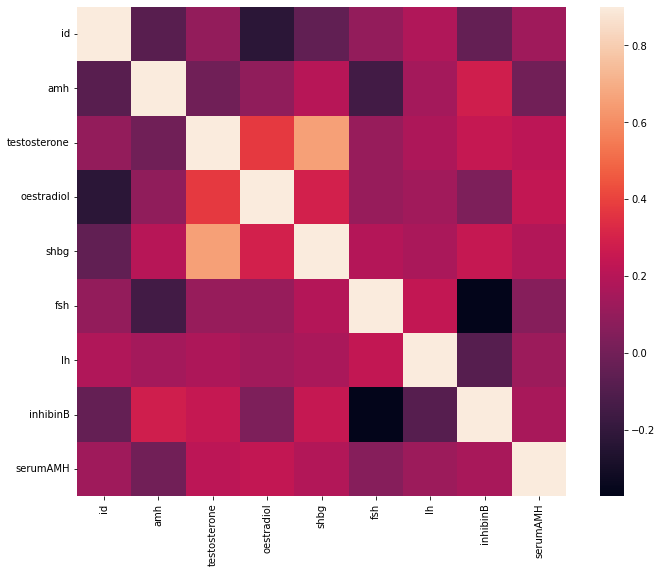

In [19]:
#Correlation map to see how features are correlated with each other and with target
corrmat = df.corr(method='kendall')
plt.subplots(figsize=(12,9))
sns.heatmap(corrmat, vmax=0.9, square=True);